## Parte 2 – Mapas del Perú

Mapeamos las declaratorias de emergencia por lluvias y la lluvia acumulada, con fecha desde el 1 de enero al 31 de mayo de 2025, por departamento, cruzando nuestros datos con el mapa oficial por ubigeo.

In [1]:
import pandas as pd
import geopandas as gpd
import folium

Paso 1 · Asegurarse de cargar los datos y el mapa

In [2]:
FUENTE = "Fuente: decretos supremos de la PCM (gob.pe), enero a mayo de 2025."

datos = pd.read_csv("datos/dataset.csv", dtype={"ubigeo": str}, encoding="utf-8-sig")
ubigeos = pd.read_csv("datos/ubigeos.csv", dtype={"ubigeo": str}, encoding="utf-8-sig")
formas = gpd.read_file("datos/departamentos.geojson")
print("Datos:", datos.shape, "| Formas:", formas.shape, "| CRS:", formas.crs)
formas.head()

Datos: (25, 9) | Formas: (25, 2) | CRS: EPSG:4326


,departamento,geometry
0,AMAZONAS,"POLYGON ((-78.03025 -6.7661, -78.04983 -6.6838..."
1,ANCASH,"POLYGON ((-77.69239 -10.3209, -77.75251 -10.32..."
2,APURIMAC,"POLYGON ((-73.51174 -14.53852, -73.52075 -14.5..."
3,AREQUIPA,"POLYGON ((-72.72968 -16.64631, -72.77421 -16.6..."
4,AYACUCHO,"POLYGON ((-74.50188 -15.16058, -74.51267 -15.1..."


Cargamos la tabla de la Assignment 2 y el mapa departamental de la sesión 7. El ubigeo se lee con `dtype=str` para que conserve el cero de la izquierda ("01", no 1).

Paso 2 · Darle el ubigeo oficial a cada forma

In [3]:
def normalizar(nombre):
    nombre = nombre.upper()
    for con_tilde, sin_tilde in [("Á", "A"), ("É", "E"), ("Í", "I"), ("Ó", "O"), ("Ú", "U")]:
        nombre = nombre.replace(con_tilde, sin_tilde)
    return nombre.strip()

ubigeos["nombre_mapa"] = ubigeos["departamento"].apply(normalizar)
formas = formas.merge(ubigeos[["ubigeo", "nombre_mapa"]],
                      left_on="departamento", right_on="nombre_mapa", how="left")

# debe salir []
print("Formas sin ubigeo:", list(formas.loc[formas["ubigeo"].isna(), "departamento"]))


Formas sin ubigeo: []


El mapa de la sesion 7 solo trae el nombre del departamento en mayúsculas y sin tildes (ANCASH, SAN MARTIN), no contiene ubigeo. Le asignamos el ubigeo oficial del INEI (`ubigeos.csv`) comparando los nombres sin tildes ni mayúsculas. 
Los 25 departamentos encontraron su código.

Paso 3 · Cruce por ubigeo como texto y reporte de lo que no cruzó

In [4]:
print("Mapa :", formas["ubigeo"].dtype, "| ejemplo:", formas["ubigeo"].iloc[0])
print("Datos:", datos["ubigeo"].dtype, "| ejemplo:", datos["ubigeo"].iloc[0])

print("En el mapa y no en los datos:", sorted(set(formas["ubigeo"]) - set(datos["ubigeo"])))
print("En los datos y no en el mapa:", sorted(set(datos["ubigeo"]) - set(formas["ubigeo"])))

mapa = formas[["ubigeo", "geometry"]].merge(datos, on="ubigeo", how="left")
print("Departamentos con datos:", mapa["declaratorias"].notna().sum(), "de", len(mapa))

Mapa : object | ejemplo: 01
Datos: object | ejemplo: 01
En el mapa y no en los datos: []
En los datos y no en el mapa: []
Departamentos con datos: 25 de 25


In [5]:
# Qué pasaría si el ubigeo se leyera como número
datos_numero = pd.read_csv("datos/dataset.csv", encoding="utf-8-sig")
print("Leído como número:", datos_numero["ubigeo"].head(3).tolist())
comunes = set(formas["ubigeo"]) & set(datos_numero["ubigeo"].astype(str))
print("Coinciden:", len(comunes), "de 25")

Leído como número: [1, 2, 3]
Coinciden: 16 de 25


Cruzamos el mapa y los datos por ubigeo, no por nombre. El reporte muestra que no quedó ningún código sin cruzar: los 25 departamentos tienen datos. Si el ubigeo se leyera como número, "01" pasaría a ser 1 y solo cruzarían 16 de 25: se perderían los nueve departamentos con código del 01 al 09.

Paso 4 · Dos coropletas estáticas por cuantiles

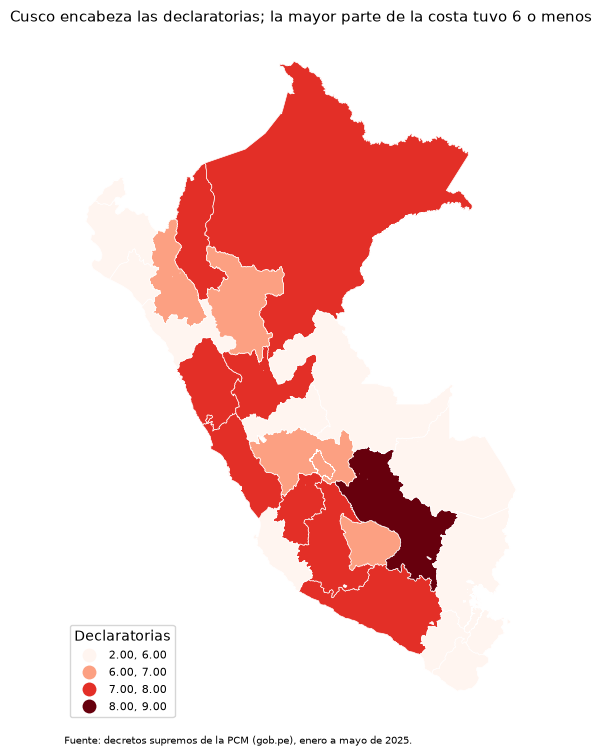

In [6]:
ax = mapa.plot(column="declaratorias", cmap="Reds", scheme="quantiles", k=4,
               legend=True, figsize=(7, 9), edgecolor="white", linewidth=0.5,
               legend_kwds={"loc": "lower left", "fontsize": 8, "title": "Declaratorias"})
ax.set_title("Cusco encabeza las declaratorias; la mayor parte de la costa tuvo 6 o menos", fontsize=11)
ax.annotate(FUENTE, xy=(0, -0.03), xycoords="axes fraction", fontsize=7)
ax.set_axis_off()

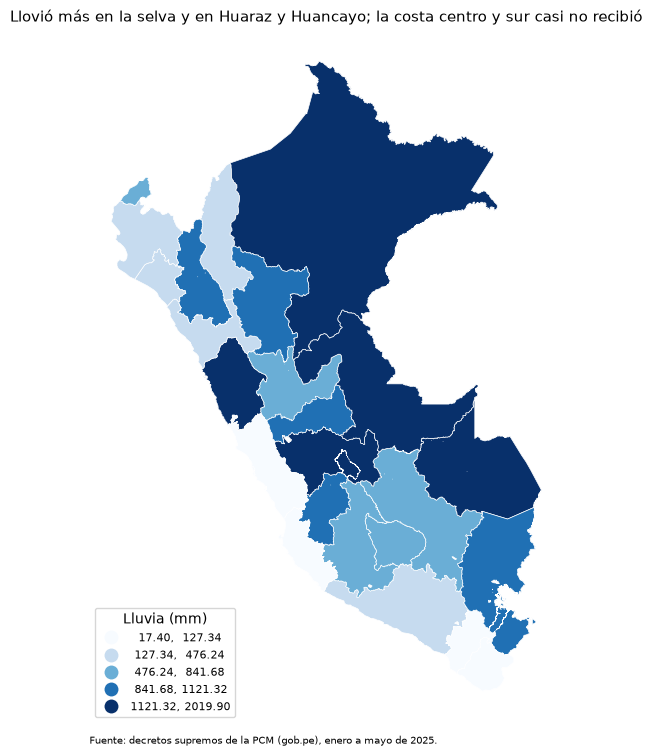

In [7]:
ax = mapa.plot(column="lluvia_total_mm", cmap="Blues", scheme="quantiles", k=5,
               legend=True, figsize=(7, 9), edgecolor="white", linewidth=0.5,
               legend_kwds={"loc": "lower left", "fontsize": 8, "title": "Lluvia (mm)"})
ax.set_title("Llovió más en la selva y en Huaraz y Huancayo; la costa centro y sur casi no recibió", fontsize=11)
ax.annotate(FUENTE, xy=(0, -0.03), xycoords="axes fraction", fontsize=7)
ax.set_axis_off()

Usamos cuantiles `scheme="quantiles"`, para repartir los departamentos en grupos parecidos; con una escala lineal, Loreto y Madre de Dios dejarían a casi todos los demás del mismo color. En las declaratorias los grupos no quedan iguales porque hay muchos empates (ocho departamentos tienen 8).

Paso 5 · Mapa interactivo con Folium

In [ ]:
m = folium.Map(location=[-9.2, -75.0], zoom_start=5, tiles="OpenStreetMap")

folium.Choropleth(
    geo_data=mapa, data=mapa,
    columns=["ubigeo", "declaratorias"],
    key_on="feature.properties.ubigeo",
    fill_color="YlOrRd", fill_opacity=0.7, line_opacity=0.4,
    legend_name="Declaratorias de emergencia por lluvias (enero a mayo de 2025)",
).add_to(m)

folium.GeoJson(
    mapa,
    style_function=lambda x: {"fillOpacity": 0, "weight": 0},
    tooltip=folium.GeoJsonTooltip(
        fields=["departamento", "declaratorias", "lluvia_total_mm", "dias_lluvia_fuerte"],
        aliases=["Departamento:", "Declaratorias:", "Lluvia (mm):", "Días ≥ 20 mm:"],
    ),
).add_to(m)

m.save("mapa_interactivo.html")
m

El `Choropleth` pinta las declaratorias y la capa `GeoJson` agrega el tooltip: al pasar el cursor se ve el departamento, sus declaratorias, la lluvia y los días de lluvia fuerte. 

Paso 6 · Guardar el mapa con ubigeo, para el dashboard

In [9]:
formas[["ubigeo", "departamento", "geometry"]].to_file(
    "datos/departamentos_ubigeo.geojson", driver="GeoJSON")
print("Guardado")

Guardado


Guardamos las formas con su ubigeo para que el dashboard de la Parte 3 cruce por código.

Paso 7 · Patrón geográfico: el mapa frente a los gráficos (texto)

**¿Qué muestra el mapa que no mostraban los gráficos?**

La lluvia y las declaratorias tienen geografías distintas. La lluvia alta se concentra en el oriente (Loreto, Madre de Dios, Ucayali), además de Huaraz y Huancayo, mientras la costa centro y sur casi no recibió lluvia. Las declaratorias, en cambio, son altas en la mayoría de departamentos andinos del centro y del sur, y en Amazonas y Loreto; la mayor parte de la costa tuvo 6 o menos. El contraste más claro es Madre de Dios: está entre los más lluviosos, pero en el grupo más bajo de declaratorias. En el gráfico de dispersión eso era un punto suelto; en el mapa se ve que la emergencia no siguió a la lluvia.
